In [1]:
# Interpretable Postpartum Anxiety Symptom Screening Using Confidence-Gated Hybrid Machine Learning
# Notebook 02: hybrid models, full model comparison, and explainable AI (SHAP vs LIME)

# Task 1: Import libraries
import time
import warnings
from pathlib import Path

import lime
import lime.lime_tabular
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import shap
import sklearn
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import RFE
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier, VotingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, matthews_corrcoef, recall_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVC

# SHAP prints a progress bar; the explanation results are unaffected.
warnings.filterwarnings("ignore", category=FutureWarning)

/Volumes/Fullstack/Github/research-projects/01-postpartum-anxiety-cgth/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Task 2: Settings (fixed before the final run)
DATA_FILE = "../data/raw/postpartum_depression.csv"
RESULTS_FOLDER = Path("../results/hybrid_xai")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

TARGET = "Feeling anxious"
SEED = 42            # final run; hybrid designs were chosen earlier on seeds 7 and 2026
DELTA = 0.2          # confidence gate, same value as notebook 01
N_SPLITS, N_REPEATS = 5, 10

versions = (f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
            f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | "
            f"shap {shap.__version__} | lime 0.2.0.1")
(RESULTS_FOLDER / "library_versions.txt").write_text(versions)
print(versions)

numpy 2.4.6 | pandas 3.1.0 | scipy 1.17.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | shap 0.51.0 | lime 0.2.0.1


In [3]:
# Task 3: Load the dataset (the CSV file is only read, never changed)
raw = pd.read_csv(DATA_FILE)
print("Rows and columns:", raw.shape)

Rows and columns: (1503, 11)


In [4]:
# Task 4: Data audit - duplicates and missing values
answers = raw.drop(columns="Timestamp")
unique_rows = answers.drop_duplicates().reset_index(drop=True)

print("Duplicate rows removed:", answers.duplicated().sum())
print("Unique rows used:", len(unique_rows))
print("Missing cells:", unique_rows.isna().sum().sum())

Duplicate rows removed: 1177
Unique rows used: 326
Missing cells: 9


In [5]:
# Task 5: Features (X) and target (y)
X = unique_rows.drop(columns=TARGET).astype(object)
y = (unique_rows[TARGET] == "Yes").astype(int).to_numpy()

# Short names make the explanation plots readable
SHORT_NAMES = {
    "Age": "Age",
    "Feeling sad or Tearful": "Sad / tearful",
    "Irritable towards baby & partner": "Irritable",
    "Trouble sleeping at night": "Sleep trouble",
    "Problems concentrating or making decision": "Concentration",
    "Overeating or loss of appetite": "Appetite",
    "Feeling of guilt": "Guilt",
    "Problems of bonding with baby": "Bonding",
    "Suicide attempt": "Suicide item",
}
print("Positive rate (Feeling anxious = Yes):", round(y.mean(), 3))

Positive rate (Feeling anxious = Yes): 0.58


In [6]:
# Task 6: Preprocessing - learned inside each training fold, so the test fold never leaks
def one_hot():
    return make_pipeline(SimpleImputer(strategy="most_frequent"),
                         OneHotEncoder(handle_unknown="ignore"))


def ordinal():
    return make_pipeline(SimpleImputer(strategy="most_frequent"), OrdinalEncoder())

In [7]:
# Task 7: Single models (the comparison baselines)
def logistic_regression():
    return make_pipeline(one_hot(), LogisticRegression(max_iter=2000))


def random_forest():
    return make_pipeline(one_hot(), RandomForestClassifier(
        n_estimators=300, max_depth=6, min_samples_leaf=3, random_state=SEED))


def extra_trees():
    return make_pipeline(one_hot(), ExtraTreesClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=3, random_state=SEED))


def svm():
    # Calibration turns SVM scores into probabilities
    return make_pipeline(one_hot(), CalibratedClassifierCV(SVC(C=1), ensemble=False, cv=5))


def naive_bayes():
    return make_pipeline(ordinal(), CategoricalNB(min_categories=5))


def gradient_boosting():
    return make_pipeline(ordinal(), HistGradientBoostingClassifier(
        categorical_features=[True] * 9, max_depth=3, learning_rate=0.05, random_state=SEED))

In [8]:
# Task 8: Hybrid ensemble (HE) - soft voting of three different learners
# Random Forest (bagging), Extra Trees (random splits) and SVM (margin-based) make
# different kinds of errors, so averaging their probabilities steadies the prediction.
def hybrid_ensemble():
    return VotingClassifier([("rf", random_forest()), ("et", extra_trees()), ("svm", svm())],
                            voting="soft")


# Common hybrid used in the literature, kept as a comparison
def stacking():
    return StackingClassifier([("rf", random_forest()), ("et", extra_trees()), ("nb", naive_bayes())],
                              final_estimator=LogisticRegression(max_iter=1000), cv=5)

In [9]:
# Task 9: Proposed hybrid - Confidence-Gated Hybrid Ensemble (CG-HE)
# Stage 1: Logistic Regression (fully explainable) decides every case it is confident about.
# Stage 2: uncertain cases (probability within DELTA of 0.5) go to a stronger fallback model.
FALLBACKS = {"Hybrid Ensemble": hybrid_ensemble, "Random Forest": random_forest}


class ConfidenceGatedHybrid(ClassifierMixin, BaseEstimator):
    def __init__(self, delta=DELTA, fallback="Hybrid Ensemble"):
        self.delta = delta
        self.fallback = fallback

    def fit(self, X, y):
        self.transparent_ = logistic_regression().fit(X, y)
        self.fallback_ = FALLBACKS[self.fallback]().fit(X, y)
        self.classes_ = np.array([0, 1])
        return self

    def decided_by_lr(self, X):
        return np.abs(self.transparent_.predict_proba(X)[:, 1] - 0.5) >= self.delta

    def predict_proba(self, X):
        lr_prob = self.transparent_.predict_proba(X)[:, 1]
        fallback_prob = self.fallback_.predict_proba(X)[:, 1]
        prob = np.where(self.decided_by_lr(X), lr_prob, fallback_prob)
        return np.column_stack([1 - prob, prob])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [10]:
# Task 10: All models in one place
models = {
    "Logistic Regression": logistic_regression(),
    "Random Forest": random_forest(),
    "Extra Trees": extra_trees(),
    "SVM": svm(),
    "Naive Bayes": naive_bayes(),
    "Gradient Boosting": gradient_boosting(),
    "Stacking (RF+ET+NB)": stacking(),
    "CGTH (LR→RF, notebook 01)": ConfidenceGatedHybrid(fallback="Random Forest"),
    "HE: Hybrid Ensemble (proposed)": hybrid_ensemble(),
    "CG-HE: Gated Hybrid (proposed)": ConfidenceGatedHybrid(fallback="Hybrid Ensemble"),
}
HYBRIDS = ["Stacking (RF+ET+NB)", "CGTH (LR→RF, notebook 01)",
           "HE: Hybrid Ensemble (proposed)", "CG-HE: Gated Hybrid (proposed)"]

In [11]:
# Task 11: Evaluation metrics (threshold 0.5)
def lr_coverage(estimator, X, y):
    # Share of decisions made by the transparent Logistic Regression (gated models only)
    return estimator.decided_by_lr(X).mean() if hasattr(estimator, "decided_by_lr") else np.nan


SCORING = {
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
    "sensitivity": "recall",
    "specificity": make_scorer(recall_score, pos_label=0),
    "f1": "f1",
    "mcc": make_scorer(matthews_corrcoef),
    "roc_auc": "roc_auc",
    "lr_coverage": lr_coverage,
}
METRICS = [m for m in SCORING if m != "lr_coverage"]

In [12]:
# Task 12: Experiment - 5-fold cross-validation repeated 10 times (50 folds), train and test scores
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

rows = []
for name, model in models.items():
    result = cross_validate(model, X, y, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    for fold in range(N_SPLITS * N_REPEATS):
        for part in ["train", "test"]:
            row = {"model": name, "fold": fold, "part": part}
            row.update({m: result[f"{part}_{m}"][fold] for m in SCORING})
            rows.append(row)

fold_scores = pd.DataFrame(rows)
fold_scores.to_csv(RESULTS_FOLDER / "fold_scores.csv", index=False)
print("Cross-validation finished:", len(models), "models x", N_SPLITS * N_REPEATS, "folds")

Cross-validation finished: 10 models x 50 folds


In [13]:
# Task 13: Test results - mean with corrected 95% confidence interval
# The Nadeau-Bengio correction widens the interval because CV training sets overlap.
N_TEST = len(y) / N_SPLITS
N_TRAIN = len(y) - N_TEST


def corrected_se(values):
    return np.sqrt((1 / len(values) + N_TEST / N_TRAIN) * np.var(values, ddof=1))


def mean_with_ci(values):
    margin = stats.t.ppf(0.975, len(values) - 1) * corrected_se(values)
    return f"{values.mean():.3f} [{values.mean() - margin:.3f}, {values.mean() + margin:.3f}]"


test_scores = fold_scores[fold_scores["part"] == "test"]
test_table = test_scores.groupby("model", sort=False)[METRICS].agg(mean_with_ci)
test_table["lr_coverage"] = test_scores.groupby("model", sort=False)["lr_coverage"].mean().round(3)
test_table.to_csv(RESULTS_FOLDER / "test_results.csv")
test_table

,balanced_accuracy,accuracy,sensitivity,specificity,f1,mcc,roc_auc,lr_coverage
model,,,,,,,,
Logistic Regression,"0.730 [0.667, 0.794]","0.745 [0.682, 0.808]","0.821 [0.749, 0.893]","0.639 [0.553, 0.726]","0.788 [0.733, 0.843]","0.473 [0.343, 0.603]","0.800 [0.740, 0.859]",NaN
Random Forest,"0.771 [0.718, 0.824]","0.785 [0.734, 0.837]","0.861 [0.798, 0.923]","0.681 [0.596, 0.765]","0.823 [0.778, 0.867]","0.558 [0.451, 0.664]","0.843 [0.795, 0.890]",NaN
Extra Trees,"0.760 [0.710, 0.810]","0.770 [0.721, 0.820]","0.825 [0.757, 0.893]","0.695 [0.618, 0.773]","0.806 [0.760, 0.851]","0.529 [0.427, 0.630]","0.848 [0.801, 0.895]",NaN
SVM,"0.767 [0.715, 0.819]","0.781 [0.729, 0.832]","0.853 [0.785, 0.921]","0.680 [0.598, 0.762]","0.818 [0.772, 0.864]","0.549 [0.442, 0.655]","0.822 [0.772, 0.873]",NaN
Naive Bayes,"0.732 [0.669, 0.795]","0.748 [0.687, 0.809]","0.833 [0.763, 0.902]","0.631 [0.533, 0.730]","0.793 [0.740, 0.845]","0.479 [0.351, 0.607]","0.814 [0.757, 0.871]",NaN
Gradient Boosting,"0.737 [0.683, 0.790]","0.749 [0.695, 0.802]","0.813 [0.737, 0.888]","0.661 [0.580, 0.741]","0.788 [0.739, 0.838]","0.483 [0.374, 0.592]","0.818 [0.765, 0.871]",NaN
Stacking (RF+ET+NB),"0.766 [0.710, 0.821]","0.778 [0.724, 0.833]","0.844 [0.774, 0.915]","0.687 [0.603, 0.772]","0.815 [0.766, 0.863]","0.545 [0.431, 0.658]","0.843 [0.794, 0.892]",NaN
"CGTH (LR→RF, notebook 01)","0.757 [0.700, 0.814]","0.774 [0.719, 0.829]","0.860 [0.796, 0.924]","0.655 [0.569, 0.740]","0.815 [0.768, 0.862]","0.533 [0.417, 0.649]","0.811 [0.755, 0.868]",0.684
HE: Hybrid Ensemble (proposed),"0.772 [0.720, 0.824]","0.785 [0.734, 0.836]","0.854 [0.788, 0.921]","0.690 [0.608, 0.771]","0.821 [0.776, 0.867]","0.558 [0.453, 0.664]","0.843 [0.794, 0.891]",NaN


In [14]:
# Task 14: Training vs testing - is any model overfitting?
mean_scores = fold_scores.groupby(["model", "part"], sort=False)[["balanced_accuracy", "roc_auc"]].mean()
train_test = mean_scores.unstack("part")
train_test.columns = [f"{metric}_{part}" for metric, part in train_test.columns]
train_test["balanced_accuracy_gap"] = train_test["balanced_accuracy_train"] - train_test["balanced_accuracy_test"]
train_test["roc_auc_gap"] = train_test["roc_auc_train"] - train_test["roc_auc_test"]
train_test = (train_test * 100).round(1)
train_test.to_csv(RESULTS_FOLDER / "train_vs_test.csv")
train_test

,balanced_accuracy_train,balanced_accuracy_test,roc_auc_train,roc_auc_test,balanced_accuracy_gap,roc_auc_gap
model,,,,,,
Logistic Regression,77.6,73.0,85.9,80.0,4.5,5.9
Random Forest,84.6,77.1,96.0,84.3,7.5,11.7
Extra Trees,93.1,76.0,99.0,84.8,17.1,14.2
SVM,86.2,76.7,97.1,82.2,9.6,14.8
Naive Bayes,76.2,73.2,85.3,81.4,3.0,3.9
Gradient Boosting,83.9,73.7,93.6,81.8,10.3,11.8
Stacking (RF+ET+NB),85.9,76.6,96.3,84.3,9.3,12.0
"CGTH (LR→RF, notebook 01)",83.2,75.7,89.2,81.1,7.4,8.0
HE: Hybrid Ensemble (proposed),87.4,77.2,97.5,84.3,10.2,13.2


In [15]:
# Task 15: Ranking - which model is best on balanced accuracy and ROC-AUC together?
ranking = test_scores.groupby("model", sort=False)[["balanced_accuracy", "roc_auc"]].mean()
ranking["rank_balanced_accuracy"] = ranking["balanced_accuracy"].rank(ascending=False)
ranking["rank_roc_auc"] = ranking["roc_auc"].rank(ascending=False)
ranking["average_rank"] = ranking[["rank_balanced_accuracy", "rank_roc_auc"]].mean(axis=1)
ranking = ranking.sort_values("average_rank")
ranking[["balanced_accuracy", "roc_auc"]] = (ranking[["balanced_accuracy", "roc_auc"]] * 100).round(1)
ranking.to_csv(RESULTS_FOLDER / "model_ranking.csv")
print("Best on both metrics together:", ranking.index[0])
ranking

Best on both metrics together: HE: Hybrid Ensemble (proposed)


,balanced_accuracy,roc_auc,rank_balanced_accuracy,rank_roc_auc,average_rank
model,,,,,
HE: Hybrid Ensemble (proposed),77.2,84.3,1.0,3.0,2.0
Random Forest,77.1,84.3,2.0,4.0,3.0
Extra Trees,76.0,84.8,5.0,1.0,3.0
Stacking (RF+ET+NB),76.6,84.3,4.0,2.0,3.0
SVM,76.7,82.2,3.0,5.0,4.0
Gradient Boosting,73.7,81.8,8.0,6.0,7.0
CG-HE: Gated Hybrid (proposed),75.9,81.2,6.0,8.0,7.0
Naive Bayes,73.2,81.4,9.0,7.0,8.0
"CGTH (LR→RF, notebook 01)",75.7,81.1,7.0,9.0,8.0


In [16]:
# Task 16: Statistical test - are the two proposed hybrids different from each other model?
# Two-sided corrected paired t-test on balanced accuracy, Holm correction for many comparisons
PROPOSED = ["HE: Hybrid Ensemble (proposed)", "CG-HE: Gated Hybrid (proposed)"]
per_fold = test_scores.pivot(index="fold", columns="model", values="balanced_accuracy")
k = len(per_fold)

rows = []
for hybrid in PROPOSED:
    for name in models:
        if name == hybrid:
            continue
        difference = per_fold[hybrid] - per_fold[name]
        t = difference.mean() / corrected_se(difference)
        rows.append({"hybrid": hybrid, "compared_with": name, "difference": difference.mean(),
                     "p": 2 * stats.t.sf(abs(t), df=k - 1)})

tests = pd.DataFrame(rows).sort_values("p")
tests["p_holm"] = (tests["p"] * np.arange(len(tests), 0, -1)).cummax().clip(upper=1)
tests["significant"] = tests["p_holm"] < 0.05
tests = tests.sort_values(["hybrid", "difference"], ascending=[False, False]).round(4)
tests.to_csv(RESULTS_FOLDER / "hybrids_vs_others.csv", index=False)
tests

,hybrid,compared_with,difference,p,p_holm,significant
0,HE: Hybrid Ensemble (proposed),Logistic Regression,0.0418,0.0383,0.6504,False
4,HE: Hybrid Ensemble (proposed),Naive Bayes,0.0400,0.0609,0.9742,False
5,HE: Hybrid Ensemble (proposed),Gradient Boosting,0.0355,0.0116,0.2093,False
7,HE: Hybrid Ensemble (proposed),"CGTH (LR→RF, notebook 01)",0.0146,0.1795,1.0000,False
8,HE: Hybrid Ensemble (proposed),CG-HE: Gated Hybrid (proposed),0.0130,0.1339,1.0000,False
2,HE: Hybrid Ensemble (proposed),Extra Trees,0.0119,0.2761,1.0000,False
6,HE: Hybrid Ensemble (proposed),Stacking (RF+ET+NB),0.0062,0.4262,1.0000,False
3,HE: Hybrid Ensemble (proposed),SVM,0.0053,0.4692,1.0000,False
1,HE: Hybrid Ensemble (proposed),Random Forest,0.0012,0.8785,1.0000,False
9,CG-HE: Gated Hybrid (proposed),Logistic Regression,0.0288,0.0953,1.0000,False


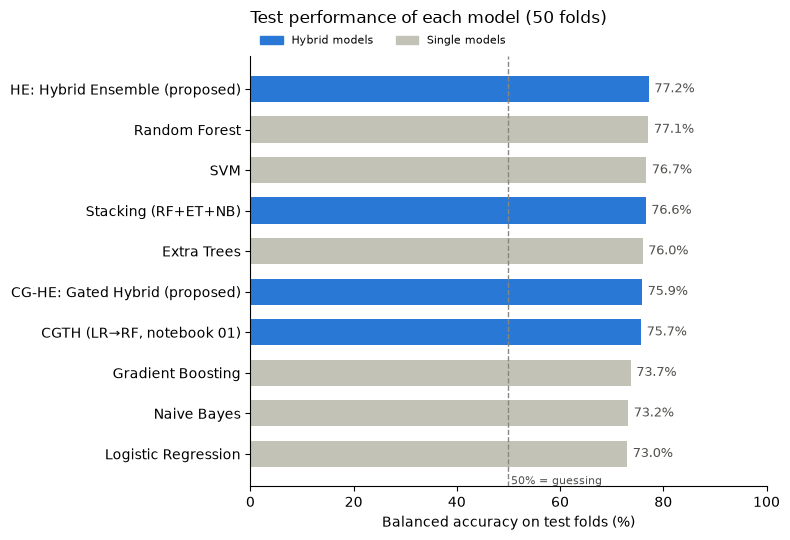

In [17]:
# Task 17: Figure - test balanced accuracy of every model
chart = ranking.sort_values("balanced_accuracy")
is_hybrid = chart.index.isin(HYBRIDS)

plt.figure(figsize=(8, 5.5))
bars = plt.barh(chart.index, chart["balanced_accuracy"], height=0.65,
                color=np.where(is_hybrid, "#2a78d6", "#c3c2b7"))
plt.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9, color="#52514e")
plt.axvline(50, color="#898781", linewidth=1, linestyle="--")
plt.text(50.5, -0.75, "50% = guessing", fontsize=8, color="#52514e")
plt.legend(handles=[Patch(color="#2a78d6", label="Hybrid models"),
                    Patch(color="#c3c2b7", label="Single models")],
           loc="lower left", bbox_to_anchor=(0, 1), ncol=2, fontsize=8, frameon=False)
plt.xlim(0, 100)
plt.xlabel("Balanced accuracy on test folds (%)")
plt.title("Test performance of each model (50 folds)", loc="left", fontsize=12, pad=24)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "model_comparison.png", dpi=300)
plt.show()

In [18]:
# Task 18: Context from related studies (different datasets - NOT a direct comparison)
# Values are as reported by each paper (see research_plan/03_literature_review_and_gaps.md).
he = ranking.loc["HE: Hybrid Ensemble (proposed)"]
cghe = ranking.loc["CG-HE: Gated Hybrid (proposed)"]
literature = pd.DataFrame([
    ["Zhang et al. 2020, JMIR Med Inform", "Chinese cohort, 508 women", "PPD", "AUC 0.78"],
    ["Amit et al. 2021, BMC Pregnancy Childbirth", "UK EHR, 266,544 women", "PPD diagnosis/treatment", "AUC 0.72-0.74"],
    ["Saqib et al. 2021, scoping review", "14 studies", "PPD", "AUC 0.78-0.93"],
    ["Huang et al. 2025, Front Med", "Clinical cohort", "PPD", "AUC 0.955 (10-fold CV)"],
    ["Adhikari & Karki 2026", "Bangladesh, 800 women", "3 EPDS risk tiers", "Accuracy 76.5-77.4%, AUC 0.91-0.92"],
    ["Nayee et al. 2026, ICSUMMIT", "Kaggle, 1,503 entries (likely this dataset)", "Not stated", "Accuracy 96.99% (see Task 30)"],
    ["This study: HE", "Kaggle survey, 326 unique rows", "Self-reported anxiety item",
     f"Balanced accuracy {he['balanced_accuracy']}%, AUC {he['roc_auc'] / 100:.3f}"],
    ["This study: CG-HE", "Kaggle survey, 326 unique rows", "Self-reported anxiety item",
     f"Balanced accuracy {cghe['balanced_accuracy']}%, AUC {cghe['roc_auc'] / 100:.3f}"],
], columns=["study", "data", "outcome", "reported result"])
literature.to_csv(RESULTS_FOLDER / "literature_context.csv", index=False)
literature

,study,data,outcome,reported result
0,"Zhang et al. 2020, JMIR Med Inform","Chinese cohort, 508 women",PPD,AUC 0.78
1,"Amit et al. 2021, BMC Pregnancy Childbirth","UK EHR, 266,544 women",PPD diagnosis/treatment,AUC 0.72-0.74
2,"Saqib et al. 2021, scoping review",14 studies,PPD,AUC 0.78-0.93
3,"Huang et al. 2025, Front Med",Clinical cohort,PPD,AUC 0.955 (10-fold CV)
4,Adhikari & Karki 2026,"Bangladesh, 800 women",3 EPDS risk tiers,"Accuracy 76.5-77.4%, AUC 0.91-0.92"
5,"Nayee et al. 2026, ICSUMMIT","Kaggle, 1,503 entries (likely this dataset)",Not stated,Accuracy 96.99% (see Task 30)
6,This study: HE,"Kaggle survey, 326 unique rows",Self-reported anxiety item,"Balanced accuracy 77.2%, AUC 0.843"
7,This study: CG-HE,"Kaggle survey, 326 unique rows",Self-reported anxiety item,"Balanced accuracy 75.9%, AUC 0.812"


In [19]:
# Task 19: Explainable AI setup - fit the proposed CG-HE on 80% of the data, explain the other 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
final_model = ConfidenceGatedHybrid(fallback="Hybrid Ensemble").fit(X_train, y_train)

# SHAP and LIME need numbers, so each answer is turned into a category code (0, 1, 2, ...)
train_mode = X_train.mode().iloc[0]
CATEGORIES = {col: sorted(X[col].dropna().unique()) for col in X.columns}
FEATURES = [SHORT_NAMES[col] for col in X.columns]


def encode(data):
    filled = data.fillna(train_mode)
    return np.column_stack([filled[col].map({v: i for i, v in enumerate(CATEGORIES[col])})
                            for col in X.columns]).astype(float)


def decode(codes):
    codes = np.clip(np.round(codes).astype(int), 0, None)
    return pd.DataFrame({col: np.array(CATEGORIES[col], dtype=object)[np.minimum(codes[:, j], len(CATEGORIES[col]) - 1)]
                         for j, col in enumerate(X.columns)})


def predict_both(codes):
    return final_model.predict_proba(decode(codes))


def predict_anxious(codes):
    return predict_both(codes)[:, 1]


train_codes, test_codes = encode(X_train), encode(X_test)
test_accuracy = (final_model.predict(X_test) == y_test).mean()
print("Hold-out accuracy of the explained model:", round(test_accuracy, 3))

Hold-out accuracy of the explained model: 0.803


In [20]:
# Task 20: SHAP - exact Shapley values for all 9 questions (background: 50 training rows)
def run_shap(seed):
    background = shap.utils.sample(train_codes, 50, random_state=seed)
    explainer = shap.Explainer(predict_anxious, shap.maskers.Independent(background),
                               algorithm="exact", feature_names=FEATURES)
    return explainer(test_codes)


start = time.perf_counter()
shap_result = run_shap(SEED)
shap_seconds = time.perf_counter() - start
shap_values = shap_result.values
shap_result.display_data = decode(test_codes).to_numpy()   # show answers as text in plots
print(f"SHAP time: {shap_seconds:.1f} s for {len(test_codes)} respondents")

ExactExplainer explainer:  27%|██▋       | 18/66 [00:00<?, ?it/s]

ExactExplainer explainer:  30%|███       | 20/66 [00:10<00:08,  5.61it/s]

ExactExplainer explainer:  32%|███▏      | 21/66 [00:11<00:11,  3.89it/s]

ExactExplainer explainer:  33%|███▎      | 22/66 [00:11<00:14,  3.01it/s]

ExactExplainer explainer:  35%|███▍      | 23/66 [00:11<00:14,  2.92it/s]

ExactExplainer explainer:  36%|███▋      | 24/66 [00:12<00:15,  2.70it/s]

... (41 outputs left out)

ExactExplainer explainer: 100%|██████████| 66/66 [00:29<00:00,  2.58it/s]

ExactExplainer explainer: 67it [00:29,  2.46it/s]                        

ExactExplainer explainer: 67it [00:29,  1.66it/s]

SHAP time: 29.6 s for 66 respondents


In [21]:
# Task 21: LIME - local linear explanation for each test respondent
def run_lime(seed):
    explainer = lime.lime_tabular.LimeTabularExplainer(
        train_codes, feature_names=FEATURES, class_names=["Not anxious", "Anxious"],
        categorical_features=list(range(9)),
        categorical_names={j: CATEGORIES[col] for j, col in enumerate(X.columns)},
        discretize_continuous=False, random_state=seed)
    weights = np.zeros_like(test_codes)
    for i, row in enumerate(test_codes):
        explanation = explainer.explain_instance(row, predict_both, labels=(1,),
                                                 num_features=9, num_samples=2000)
        for feature, weight in explanation.as_map()[1]:
            weights[i, feature] = weight
    return weights


start = time.perf_counter()
lime_values = run_lime(SEED)
lime_seconds = time.perf_counter() - start
print(f"LIME time: {lime_seconds:.1f} s for {len(test_codes)} respondents")

LIME time: 5.3 s for 66 respondents


In [22]:
# Task 22: SHAP vs LIME - global importance of each question (% of total importance)
shap_importance = np.abs(shap_values).mean(axis=0)
lime_importance = np.abs(lime_values).mean(axis=0)

global_importance = pd.DataFrame({
    "SHAP (%)": 100 * shap_importance / shap_importance.sum(),
    "LIME (%)": 100 * lime_importance / lime_importance.sum(),
}, index=FEATURES).round(1).sort_values("SHAP (%)", ascending=False)
global_importance["SHAP rank"] = global_importance["SHAP (%)"].rank(ascending=False).astype(int)
global_importance["LIME rank"] = global_importance["LIME (%)"].rank(ascending=False).astype(int)
global_importance.to_csv(RESULTS_FOLDER / "shap_vs_lime_global.csv")
global_importance

,SHAP (%),LIME (%),SHAP rank,LIME rank
Guilt,40.3,41.1,1,1
Irritable,13.0,12.3,2,2
Appetite,12.3,11.8,3,3
Concentration,10.2,10.2,4,5
Suicide item,9.2,10.5,5,4
Age,5.8,5.3,6,6
Bonding,5.4,5.2,7,7
Sleep trouble,2.9,2.5,8,8
Sad / tearful,1.0,1.2,9,9


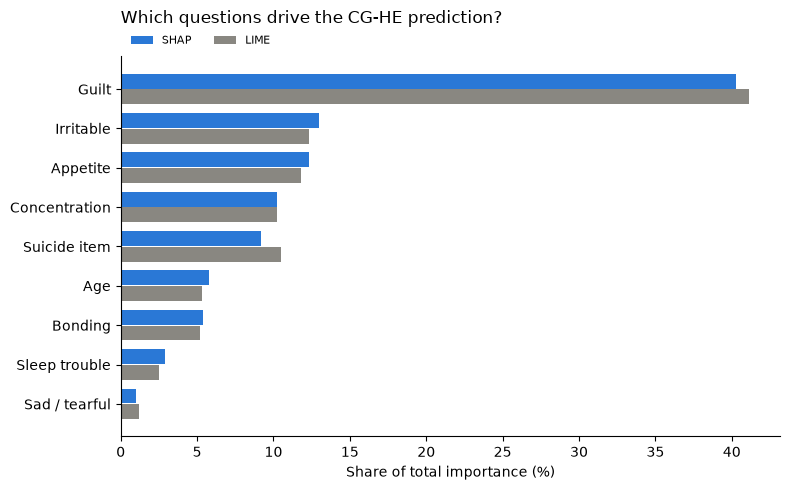

In [23]:
# Task 23: Figure - SHAP and LIME global importance side by side
chart = global_importance.sort_values("SHAP (%)")
positions = np.arange(len(chart))

plt.figure(figsize=(8, 5))
plt.barh(positions + 0.2, chart["SHAP (%)"], height=0.38, color="#2a78d6", label="SHAP")
plt.barh(positions - 0.2, chart["LIME (%)"], height=0.38, color="#898781", label="LIME")
plt.yticks(positions, chart.index)
plt.xlabel("Share of total importance (%)")
plt.title("Which questions drive the CG-HE prediction?", loc="left", fontsize=12, pad=24)
plt.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, fontsize=8, frameon=False)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "shap_vs_lime_global.png", dpi=300)
plt.show()

In [24]:
# Task 24: SHAP vs LIME - agreement, stability and speed
# Agreement: do both methods rank the questions the same way?
# Stability: does each method give the same answer when re-run with another random seed?
def row_correlation(a, b):
    return np.nanmean([spearmanr(np.abs(a[i]), np.abs(b[i]))[0] for i in range(len(a))])


shap_rerun = run_shap(SEED + 1).values
lime_rerun = run_lime(SEED + 1)

top_shap = np.abs(shap_values).argmax(axis=1)
top_lime = np.abs(lime_values).argmax(axis=1)
same_sign = np.sign(shap_values[np.arange(len(top_shap)), top_shap]) == \
            np.sign(lime_values[np.arange(len(top_shap)), top_shap])
top3_shap = set(global_importance.index[:3])
top3_lime = set(global_importance.sort_values("LIME (%)", ascending=False).index[:3])

comparison = pd.DataFrame({
    "measure": ["Global rank agreement (Spearman)", "Same top-3 questions (out of 3)",
                "Per-person rank agreement (mean Spearman)", "Same most important question per person (%)",
                "Same direction for SHAP's top question (%)",
                "SHAP stability across reruns (mean Spearman)", "LIME stability across reruns (mean Spearman)",
                "SHAP time per person (s)", "LIME time per person (s)"],
    "value": [spearmanr(shap_importance, lime_importance)[0], len(top3_shap & top3_lime),
              row_correlation(shap_values, lime_values), 100 * (top_shap == top_lime).mean(),
              100 * same_sign.mean(),
              row_correlation(shap_values, shap_rerun), row_correlation(lime_values, lime_rerun),
              shap_seconds / len(test_codes), lime_seconds / len(test_codes)],
}).round(3)
comparison.to_csv(RESULTS_FOLDER / "shap_vs_lime_comparison.csv", index=False)
comparison

ExactExplainer explainer:  36%|███▋      | 24/66 [00:00<?, ?it/s]

ExactExplainer explainer:  39%|███▉      | 26/66 [00:10<00:08,  4.82it/s]

ExactExplainer explainer:  41%|████      | 27/66 [00:10<00:11,  3.38it/s]

ExactExplainer explainer:  42%|████▏     | 28/66 [00:11<00:12,  2.94it/s]

ExactExplainer explainer:  44%|████▍     | 29/66 [00:11<00:13,  2.77it/s]

ExactExplainer explainer:  45%|████▌     | 30/66 [00:12<00:13,  2.60it/s]

... (35 outputs left out)

ExactExplainer explainer: 100%|██████████| 66/66 [00:26<00:00,  2.47it/s]

ExactExplainer explainer: 67it [00:27,  2.50it/s]                        

ExactExplainer explainer: 67it [00:27,  1.59it/s]

,measure,value
0,Global rank agreement (Spearman),0.983
1,Same top-3 questions (out of 3),3.000
2,Per-person rank agreement (mean Spearman),0.869
3,Same most important question per person (%),86.364
4,Same direction for SHAP's top question (%),100.000
5,SHAP stability across reruns (mean Spearman),0.921
6,LIME stability across reruns (mean Spearman),0.914
7,SHAP time per person (s),0.448
8,LIME time per person (s),0.080


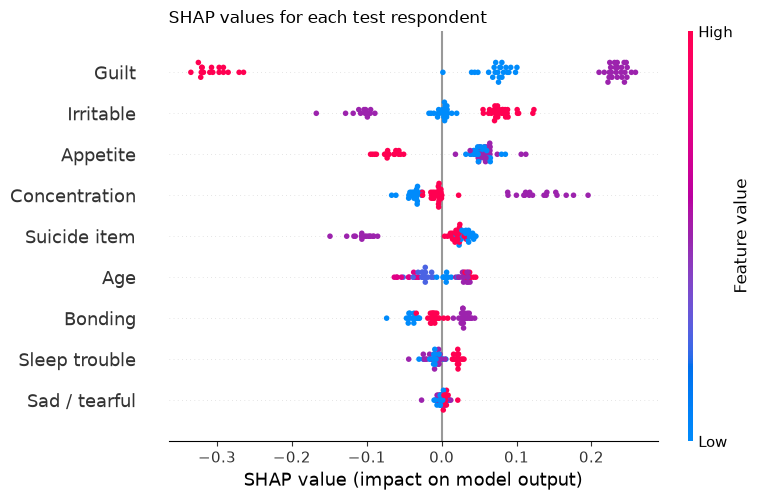

In [25]:
# Task 25: SHAP summary plot - direction of each answer's effect (colour = answer code)
shap.plots.beeswarm(shap_result, max_display=9, show=False)
plt.title("SHAP values for each test respondent", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "shap_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
# Task 26: One respondent explained by both methods (first anxious respondent in the test set)
person = int(np.where(y_test == 1)[0][0])
answers_of_person = decode(test_codes[[person]]).iloc[0]

one_person = pd.DataFrame({
    "answer": [answers_of_person[col] for col in X.columns],
    "SHAP": shap_values[person],
    "LIME": lime_values[person],
}, index=FEATURES).round(3).sort_values("SHAP", key=np.abs, ascending=False)

decided_by = "Logistic Regression" if final_model.decided_by_lr(X_test.iloc[[person]])[0] else "Hybrid Ensemble"
print("Predicted probability of anxiety:", round(predict_anxious(test_codes[[person]])[0], 3))
print("Decision made by:", decided_by)
one_person.to_csv(RESULTS_FOLDER / "one_respondent_explanation.csv")
one_person

Predicted probability of anxiety: 0.901
Decision made by: Logistic Regression


,answer,SHAP,LIME
Guilt,No,0.235,0.363
Appetite,Not at all,0.051,0.063
Age,45-50,0.031,0.038
Concentration,No,-0.027,-0.070
Bonding,Sometimes,0.027,0.055
Suicide item,Yes,0.024,0.036
Irritable,No,0.004,0.005
Sleep trouble,Two or more days a week,-0.004,-0.006
Sad / tearful,Yes,0.003,0.010


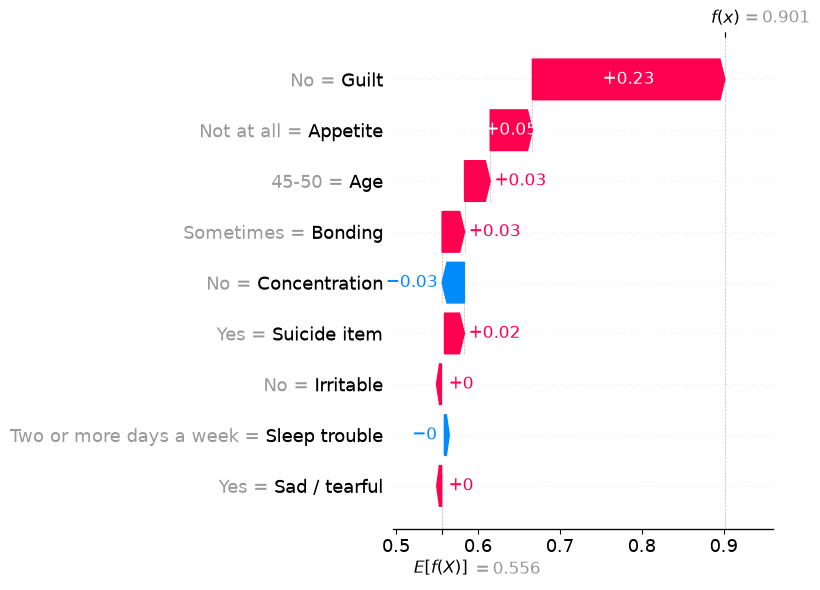

In [27]:
# Task 27: SHAP waterfall plot for the same respondent
shap.plots.waterfall(shap_result[person], max_display=9, show=False)
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "shap_waterfall_one_respondent.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
# Task 28: Transparency - how many hold-out decisions are made by the explainable Logistic Regression?
decided_by_lr = final_model.decided_by_lr(X_test)
predictions = final_model.predict(X_test)

transparency = pd.DataFrame({
    "stage": ["Logistic Regression (confident cases)", "Hybrid Ensemble (uncertain cases)", "All cases"],
    "respondents": [decided_by_lr.sum(), (~decided_by_lr).sum(), len(y_test)],
    "accuracy": [(predictions[decided_by_lr] == y_test[decided_by_lr]).mean(),
                 (predictions[~decided_by_lr] == y_test[~decided_by_lr]).mean(),
                 (predictions == y_test).mean()],
}).round(3)
transparency.to_csv(RESULTS_FOLDER / "transparency_holdout.csv", index=False)
transparency

,stage,respondents,accuracy
0,Logistic Regression (confident cases),47,0.787
1,Hybrid Ensemble (uncertain cases),19,0.842
2,All cases,66,0.803


In [29]:
# Task 29: Final summary - the key numbers of this notebook
best_single = ranking.drop(index=HYBRIDS).index[0]
summary = pd.DataFrame({
    "result": ["Best model overall (average rank)", "Best single model",
               "HE test balanced accuracy (%)", "HE test ROC-AUC (%)",
               "CG-HE test balanced accuracy (%)", "CG-HE test ROC-AUC (%)",
               "CG-HE train-test gap, balanced accuracy (points)",
               "CG-HE decisions made by Logistic Regression (%)",
               "Any hybrid significantly different from any model?",
               "Most important question (SHAP)", "Most important question (LIME)",
               "SHAP-LIME global rank agreement (Spearman)"],
    "value": [ranking.index[0], best_single,
              ranking.loc["HE: Hybrid Ensemble (proposed)", "balanced_accuracy"],
              ranking.loc["HE: Hybrid Ensemble (proposed)", "roc_auc"],
              ranking.loc["CG-HE: Gated Hybrid (proposed)", "balanced_accuracy"],
              ranking.loc["CG-HE: Gated Hybrid (proposed)", "roc_auc"],
              train_test.loc["CG-HE: Gated Hybrid (proposed)", "balanced_accuracy_gap"],
              round(100 * test_scores[test_scores["model"] == "CG-HE: Gated Hybrid (proposed)"]["lr_coverage"].mean(), 1),
              "Yes" if tests["significant"].any() else "No",
              global_importance.index[0],
              global_importance.sort_values("LIME (%)", ascending=False).index[0],
              round(spearmanr(shap_importance, lime_importance)[0], 3)],
})
summary.to_csv(RESULTS_FOLDER / "summary.csv", index=False)
summary

,result,value
0,Best model overall (average rank),HE: Hybrid Ensemble (proposed)
1,Best single model,Random Forest
2,HE test balanced accuracy (%),77.2
3,HE test ROC-AUC (%),84.3
4,CG-HE test balanced accuracy (%),75.9
5,CG-HE test ROC-AUC (%),81.2
6,"CG-HE train-test gap, balanced accuracy (points)",9.1
7,CG-HE decisions made by Logistic Regression (%),68.4
8,Any hybrid significantly different from any mo...,No
9,Most important question (SHAP),Guilt


In [30]:
# Task 30: Replicating the 96.99% accuracy reported on a 1,503-row Kaggle dataset (Nayee et al. 2026)
# Their setup kept all 1,503 rows. Here: Random Forest with RFE feature selection, 80/20 split,
# repeated on 20 random splits, once with duplicates kept and once with unique rows only.
def rfe_forest():
    return make_pipeline(ordinal(),
                         RFE(RandomForestClassifier(n_estimators=200, random_state=SEED), n_features_to_select=6),
                         RandomForestClassifier(n_estimators=200, random_state=SEED))


rows = []
for label, data in [("All 1,503 rows (duplicates kept)", answers), ("326 unique rows (this study)", unique_rows)]:
    X_all = data.drop(columns=TARGET).astype(object)
    y_all = (data[TARGET] == "Yes").astype(int).to_numpy()
    for split in range(20):
        X_a, X_b, y_a, y_b = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=split)
        accuracy = (rfe_forest().fit(X_a, y_a).predict(X_b) == y_b).mean()
        training_rows = set(map(tuple, X_a.fillna("missing").to_numpy()))
        copied = np.mean([tuple(row) in training_rows for row in X_b.fillna("missing").to_numpy()])
        rows.append({"data": label, "accuracy": accuracy, "test_rows_copied_from_training": copied})

replication = (pd.DataFrame(rows).groupby("data", sort=False).agg(["mean", "min", "max"]) * 100).round(1)
replication.to_csv(RESULTS_FOLDER / "replication_97_percent.csv")
print("Reported by Nayee et al. 2026: 96.99% accuracy")
replication

Reported by Nayee et al. 2026: 96.99% accuracy


accuracy              \
                                     mean   min   max   
data                                                    
All 1,503 rows (duplicates kept)     96.2  94.4  98.0   
326 unique rows (this study)         74.2  65.2  81.8   

                                 test_rows_copied_from_training              
                                                           mean   min   max  
data                                                                         
All 1,503 rows (duplicates kept)                           96.0  92.0  98.7  
326 unique rows (this study)                                0.0   0.0   0.0

In [31]:
# Task 31: Sample size check (Riley et al. 2020, BMJ) - is 326 rows enough for a stable model?
# Three criteria: small overfitting (shrinkage >= 0.9), small optimism in R-squared, precise overall risk.
prevalence = y.mean()
n_rows = len(y)
n_parameters = sum(X[col].nunique() - 1 for col in X.columns)    # one-hot Logistic Regression parameters
log_lik_null = n_rows * (prevalence * np.log(prevalence) + (1 - prevalence) * np.log(1 - prevalence))
max_r2 = 1 - np.exp(2 * log_lik_null / n_rows)


def required_rows(r2):
    shrinkage_rows = n_parameters / ((0.9 - 1) * np.log(1 - r2 / 0.9))
    s = r2 / (r2 + 0.05 * max_r2)
    optimism_rows = n_parameters / ((s - 1) * np.log(1 - r2 / s))
    risk_rows = (1.96 / 0.05) ** 2 * prevalence * (1 - prevalence)
    return [shrinkage_rows, optimism_rows, risk_rows, max(shrinkage_rows, optimism_rows, risk_rows)]


fitted = logistic_regression().fit(X, y).predict_proba(X)[:, 1]
log_lik_model = np.sum(y * np.log(fitted) + (1 - y) * np.log(1 - fitted))
r2_from_data = 1 - np.exp(2 * (log_lik_null - log_lik_model) / n_rows)

sample_size = pd.DataFrame(
    [required_rows(0.15 * max_r2), required_rows(r2_from_data)],
    index=["Conservative R2 (15% of maximum)", f"R2 from the fitted model ({r2_from_data:.2f})"],
    columns=["shrinkage criterion", "optimism criterion", "overall-risk criterion", "rows needed"],
).round(0)
sample_size["rows available"] = n_rows
sample_size["enough?"] = np.where(sample_size["rows needed"] <= n_rows, "Yes", "No")
sample_size.to_csv(RESULTS_FOLDER / "sample_size_check.csv")
print("Model parameters:", n_parameters)
sample_size

Model parameters: 20


,shrinkage criterion,optimism criterion,overall-risk criterion,rows needed,rows available,enough?
Conservative R2 (15% of maximum),1512.0,497.0,374.0,1512.0,326,No
R2 from the fitted model (0.34),422.0,429.0,374.0,429.0,326,No
